### Logistic Regression from Scratch — Kaggle Data

Predict pass/fail from hours studied using binary cross-entropy and batch gradient descent

#### 1. Data Source Setup & Loading

Source: [Student Performance Factors](https://www.kaggle.com/datasets/lainguyn123/student-performance-factors), uploaded by lainguyn123 on Kaggle.

File: StudentPerformanceFactors.csv, downloaded directly from Kaggle on 2026-10-18.

Hours_Studied is the only feature. Exam_Score defines the target.

In [1]:
from pathlib import Path
import csv, hashlib, io, urllib.request, zipfile
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path.cwd()
DATA_PATH = REPO_ROOT / 'data'/ "StudentPerformanceFactors.csv"


PASS_MARK = 70.0
RANDOM_SEED = 42
if not DATA_PATH.exists():
    url = 'https://www.kaggle.com/api/v1/datasets/download/lainguyn123/student-performance-factors'
    try:
        with urllib.request.urlopen(url, timeout=60) as response:
            archive = response.read()
        with zipfile.ZipFile(io.BytesIO(archive)) as bundle:
            DATA_PATH.write_bytes(bundle.read('StudentPerformanceFactors.csv'))
    except Exception as exc:
        raise RuntimeError('Download the CSV from the cited Kaggle page and place it beside this notebook.') from exc
print('CSV SHA-256:', hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())
with DATA_PATH.open(newline='', encoding='utf-8-sig') as handle:
    reader = csv.DictReader(handle)
    assert {'Hours_Studied', 'Exam_Score'} <= set(reader.fieldnames or [])
    rows = list(reader)
valid, skipped = [], 0
for row in rows:
    try:
        hours, score = float(row['Hours_Studied']), float(row['Exam_Score'])
    except (ValueError, TypeError):
        skipped += 1
        continue
    if not np.isfinite([hours, score]).all() or hours < 0:
        skipped += 1
        continue
    valid.append((hours, score))
data = np.asarray(valid, dtype=float)
assert data.ndim == 2 and len(data) > 10
X, scores = data[:, :1], data[:, 1]
y = (scores >= PASS_MARK).astype(float)
assert set(np.unique(y)) == {0., 1.}
print(f'Loaded {len(rows):,} rows; retained {len(y):,}; excluded {skipped}')
print('Hours range:', X.min(), X.max())
print('Score range:', scores.min(), scores.max())
print('Fail / Pass counts:', np.bincount(y.astype(int)))
print(f'Pass fraction: {y.mean():.3%}; pass mark: {PASS_MARK:g}')

CSV SHA-256: e8df8c4148ef83fb295ca1c092f2c6ee15272c0a8e3018b769a788ab50e96e97
Loaded 6,607 rows; retained 6,607; excluded 0
Hours range: 1.0 44.0
Score range: 55.0 101.0
Fail / Pass counts: [4982 1625]
Pass fraction: 24.595%; pass mark: 70


### 2. Show Study Hours Clearly on the Graph

The model adjusts the scale of study hours internally to make training easier. It learns this adjustment from the training data and uses the same adjustment for new students.
The graph still shows actual study hours—such as 10, 20, and 30 hours—so it is easy to read. The curve shows the predicted chance of passing at each study time.

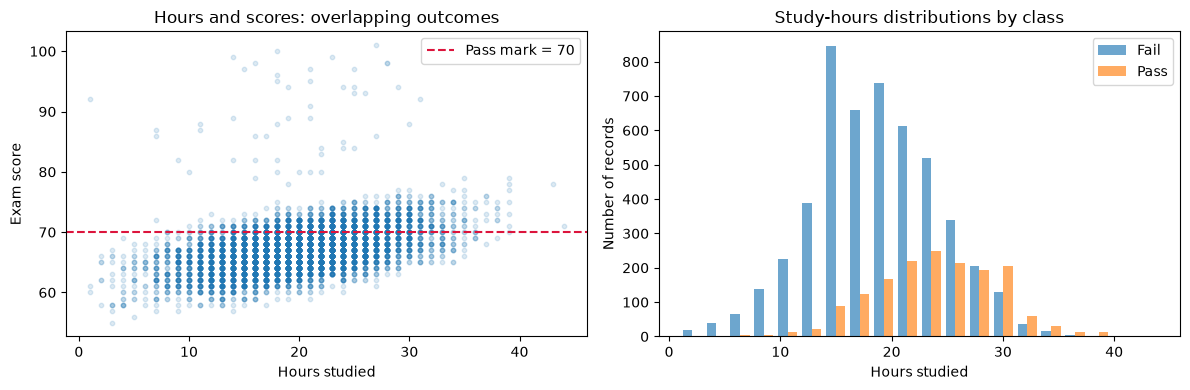

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(X.ravel(), scores, s=10, alpha=0.15)
axes[0].axhline(PASS_MARK, color='crimson', linestyle='--', label=f'Pass mark = {PASS_MARK:g}')
axes[0].set(xlabel='Hours studied', ylabel='Exam score', title='Hours and scores: overlapping outcomes')
axes[0].legend()
axes[1].hist([X[y == 0, 0], X[y == 1, 0]], bins=20, label=['Fail', 'Pass'], alpha=0.65)
axes[1].set(xlabel='Hours studied', ylabel='Number of records', title='Study-hours distributions by class')
axes[1].legend()
plt.tight_layout()
plt.show()

#### 3. Standardizing Study Hours for Consistent Predictions

We rescale study hours to help the model learn efficiently. We calculate the mean and sstandard deviation from the training data only, then use those same values to rescale both test data and new students’ study hours.he test set evaluates a fixed model and is not used for stopping or choosing the learning rate or threshold. This is a row-level split: the file has no verified student identifiers for assessing repeated individuals.
The graph still displays actual hours, making the predictions easy to understand.



In [3]:
rng = np.random.default_rng(RANDOM_SEED)
train_parts, test_parts = [], []
for label in (0, 1):
    indices = rng.permutation(np.flatnonzero(y == label))
    n_test = max(1, int(round(0.2 * len(indices))))
    assert n_test < len(indices)
    test_parts.append(indices[:n_test])
    train_parts.append(indices[n_test:])
train_idx = rng.permutation(np.concatenate(train_parts))
test_idx = rng.permutation(np.concatenate(test_parts))
X_train, X_test, y_train, y_test = X[train_idx], X[test_idx], y[train_idx], y[test_idx]
mu, scale = X_train.mean(axis=0), X_train.std(axis=0)
scale = np.where(scale == 0, 1.0, scale)
Xs_train, Xs_test = (X_train - mu) / scale, (X_test - mu) / scale
assert len(np.intersect1d(train_idx, test_idx)) == 0
print('Training / test rows:', len(train_idx), len(test_idx))
print('Training / test pass fractions:', y_train.mean(), y_test.mean())
print('Training mean / standard deviation:', mu, scale)

Training / test rows: 5286 1321
Training / test pass fractions: 0.24593265228906547 0.24602573807721423
Training mean / standard deviation: [20.00662126] [5.99963374]


#### 4. Model and binary cross-entropy derivation

For a standardized feature vector $x_i \in \mathbb{R}^d$, weights $w \in \mathbb{R}^d$, and scalar bias $b$:

$$
z_i = x_i^\top w + b, \qquad
p_i = P(y_i = 1 \mid x_i) = \sigma(z_i) = \frac{1}{1 + e^{-z_i}}.
$$

The Bernoulli likelihood for a single observation is

$$
p_i^{y_i}(1-p_i)^{1-y_i}.
$$

Assuming independent observations, taking the negative log of the product likelihood and averaging gives

$$
J(w, b) = -\frac{1}{n}\sum_{i=1}^{n}\left[y_i\log(p_i) + (1-y_i)\log(1-p_i)\right].
$$

For a passing student, the loss is $-\log(p_i)$; for a failing student, it is $-\log(1-p_i)$. A confidently wrong prediction receives a large penalty. All logarithms are natural logs.

Substituting the sigmoid gives the equivalent logit form:

$$
J = \frac{1}{n}\sum_{i=1}^{n}\left[\log(1 + e^{z_i}) - y_i z_i\right].
$$

`np.logaddexp(0, z)` evaluates the first term stably without clipping probabilities or computing $\log(0)$. The sign-split sigmoid avoids overflow from large negative inputs.


A lower training loss means the model is getting better at fitting the examples it learned from. It does not automatically mean:
- Its probabilities are reliable: Of students given a 70% chance of passing, roughly 70% should actually pass.
- More studying causes a pass: The model finds a relationship between hours and outcomes; other factors can affect results.
- It is ready for real decisions: We need more testing on new students before using it to guide student support.


In [4]:
def sigmoid(z):
    z = np.asarray(z, dtype=float)
    out = np.empty_like(z)
    positive = z >= 0
    out[positive] = 1.0 / (1.0 + np.exp(-z[positive]))
    exp_z = np.exp(z[~positive])
    out[~positive] = exp_z / (1.0 + exp_z)
    return out

def bce_from_logits(y_true, z):
    return float(np.mean(np.logaddexp(0.0, z) - y_true * z))

extreme_z = np.array([-1000., 0., 1000.])
print('Stable sigmoid:', sigmoid(extreme_z))
print('Confidently wrong extreme loss:', bce_from_logits(np.array([1., 0., 0.]), extreme_z))
assert np.isfinite(bce_from_logits(np.array([1., 0., 0.]), extreme_z))
print('Loss for y=1, p=0.95:', -np.log(0.95))
print('Loss for y=1, p=0.10:', -np.log(0.10))

Stable sigmoid: [0.  0.5 1. ]
Confidently wrong extreme loss: 666.8977157268533
Loss for y=1, p=0.95: 0.05129329438755058
Loss for y=1, p=0.10: 2.3025850929940455


5. Gradient derivation and vectorization -Calculate How the Model Should Improve

    For one observation, apply the chain rule:

    \frac{\partial p_i}{\partial z_i}=p_i(1-p_i).$$

    Multiplying and simplifying yields
    $$\frac{\partial\ell_i}{\partial z_i}=p_i-y_i.$$
    Since $\partial z_i/\partial w=x_i$ and $\partial z_i/\partial b=1$:
    $$\nabla_w J=\frac1nX^T(p-y),\qquad \frac{\partial J}{\partial b}=\frac1n\sum_i(p_i-y_i).$$
    Here `X` is `(n, d)`, `w` is `(d,)`, and `p-y` is `(n,)`; `X.T @ (p-y)` is `(d,)`. 

    The bias gradient is a scalar. Matrix multiplication handles all observations together. A finite-difference check below independently verifies both gradients at nonzero parameters.


    The model compares each student’s predicted probability of passing with their actual outcome.

    For example:
    - If a student passed, but the model predicted only a 30% chance, it should increase that student’s predicted probability.
    - If a student failed, but the model predicted an 80% chance of passing, it should decrease that probability.
    The code combines these errors across all training students to calculate how the weight and bias should change. NumPy performs these calculations for all students together.
    We also check these calculations by slightly changing the weight and bias and observing how the loss changes. This helps confirm that the code gives the correct direction for improvement.

In [5]:
def loss_and_grad(X, y, w, b):
    z = X @ w + b
    residual = sigmoid(z) - y
    return bce_from_logits(y, z), X.T @ residual / len(y), float(residual.mean())

w_probe, b_probe = np.array([0.37]), -0.21
_, dw, db = loss_and_grad(Xs_train, y_train, w_probe, b_probe)
eps = 1e-6
numeric_dw = np.empty_like(w_probe)
for j in range(len(w_probe)):
    step = np.zeros_like(w_probe)
    step[j] = eps
    numeric_dw[j] = (loss_and_grad(Xs_train, y_train, w_probe + step, b_probe)[0]
                     - loss_and_grad(Xs_train, y_train, w_probe - step, b_probe)[0]) / (2 * eps)
numeric_db = (loss_and_grad(Xs_train, y_train, w_probe, b_probe + eps)[0]
              - loss_and_grad(Xs_train, y_train, w_probe, b_probe - eps)[0]) / (2 * eps)
np.testing.assert_allclose(dw, numeric_dw, rtol=1e-5, atol=1e-7)
np.testing.assert_allclose(db, numeric_db, rtol=1e-5, atol=1e-7)
print('Analytic and numerical weight gradients:', dw, numeric_dw)
print('Analytic and numerical bias gradients:', db, numeric_db)
print('Gradient checks passed.')

Analytic and numerical weight gradients: [-0.07242048] [-0.07242048]
Analytic and numerical bias gradients: 0.20340920087748476 0.20340920081629577
Gradient checks passed.


#### 6. Batch gradient descent: algorithm and implementation

Train the model by improving its predictions step by step:

1. Initialize every weight and the bias to zero. This is suitable for logistic regression.
2. Compute logits and probabilities for the entire training set.
3. Evaluate average binary cross-entropy and both gradients.
4. Stop if the combined gradient norm is below tolerance.
5. Update both parameters using gradients from the same parameter state:
   $$
   w \leftarrow w - \alpha \nabla_w J, \qquad b \leftarrow b - \alpha \frac{\partial J}{\partial b}.
   $$
6. Repeat until convergence or the iteration limit; report which occurred.

Use learning rate $\alpha = 0.1$, gradient tolerance $10^{-7}$, and at most 50,000 updates. Each iteration costs $O(nd)$; the only training loop is over optimization steps, never individual students. 


The model starts with a weight and bias of zero, giving every student a 50% predicted chance of passing.
It then repeats these steps:
1. Predict each training student’s probability of passing.
2. Measure the mistakes using binary cross-entropy (log-loss).
3. Calculate how the weight and bias should change to reduce the loss.
4. Adjust both using a small step called the learning rate.

This process is called gradient descent. Our implementation uses all training students to calculate each update.

Training stops when the calculated adjustments become very small or the model reaches the maximum number of updates. The goal is to reduce the overall loss; some students may still be classified incorrectly.

In [6]:
def fit_logistic(X, y, learning_rate=0.1, max_iter=50_000, tol=1e-7):
    w, b = np.zeros(X.shape[1]), 0.0
    history = []
    converged = False
    for iteration in range(max_iter):
        loss, dw, db = loss_and_grad(X, y, w, b)
        history.append(loss)
        if np.sqrt(dw @ dw + db * db) < tol:
            converged = True
            break
        w, b = w - learning_rate * dw, b - learning_rate * db
    final_loss, dw, db = loss_and_grad(X, y, w, b)
    history.append(final_loss)
    converged = converged or np.sqrt(dw @ dw + db * db) < tol
    return w, b, np.array(history), converged

w, b, history, converged = fit_logistic(Xs_train, y_train)
assert np.isfinite(history).all()
assert history[-1] < history[0]
assert np.all(np.diff(history) <= 1e-12)
print('Converged:', converged)
print('Initial/final training BCE:', history[0], history[-1])
print('Standardized weight and bias:', w, b)
print('Recorded training losses:')
for k in np.unique(np.linspace(0, len(history)-1, 8, dtype=int)):
    print(f'  entry {k:5d}: {history[k]:.8f}')

Converged: True
Initial/final training BCE: 0.6931471805599453 0.4822025782295784
Standardized weight and bias: [1.02287364] -1.3490549170131019
Recorded training losses:
  entry     0: 0.69314718
  entry   226: 0.48299503
  entry   453: 0.48221695
  entry   679: 0.48220288
  entry   906: 0.48220258
  entry  1132: 0.48220258
  entry  1359: 0.48220258
  entry  1586: 0.48220258


#### 7. Inspect convergence

**Check whether the Model is learning**

The preceding optimizer uses full-batch gradients and a learning rate of 0.1. The loss should fall toward a stable minimum; the gradient norm, rather than test performance, controls stopping. A decreasing loss verifies optimization progress but does not prove generalization or calibration. The implementation remains vectorized over all students; its training loop runs over updates only.

The graph shows how the model’s training loss changes as it updates its weight and bias.
- A falling line means its predictions are improving overall on the training data.
- A line that levels off means further updates are making little difference.
- A rising or repeatedly jumping line may mean the learning rate is too large.
We stop training when the gradients become very small or the maximum number of updates is reached.
A falling training loss is encouraging, but we still need to test the model on students it has not seen before.

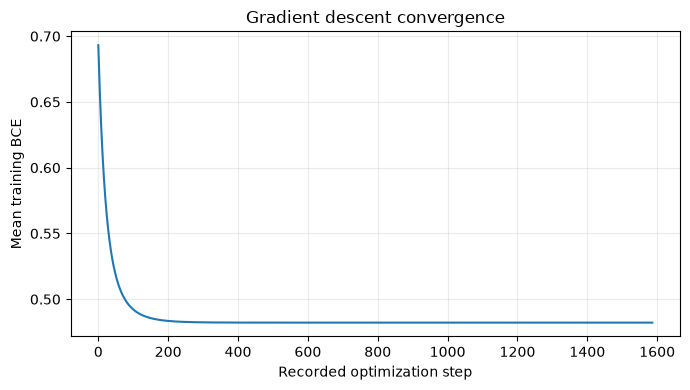

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(len(history)), history)
ax.set(xlabel='Recorded optimization step', ylabel='Mean training BCE', title='Gradient descent convergence')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

#### 8. Evaluate probabilities and classifications

**Test The Model's Predictions**

Predict $p=\sigma(Xw+b)$, then classify Pass when $p\geq0.5$. Report BCE, accuracy, precision, recall, and a confusion matrix. Accuracy should be compared with a model that always predicts the training majority class. A constant probability equal to the training pass fraction provides a BCE baseline. Precision and recall are for Pass; a zero denominator is reported as undefined.



Recover parameters on the original hours scale using $w_h=w/s$ and $b_h=b-\mu^T(w/s)$. The 0.5 boundary is $x_*=-b_h/w_h$ when $w_h\ne0$. Larger hours need not be associated with passing in every possible dataset; inspect the learned sign. This is association, not a causal estimate.


We check the model using students it did not see during training.
For each student, the model predicts a probability of passing. We turn that probability into a decision:
- 50% or higher → Pass
- Below 50% → Fail
We measure performance using:

| Measure | What it tells us |
| :--- | :--- |
| Log-loss (BCE) | How good are the predicted probabilities? Lower is better. |
| Accuracy | What percentage of students were classified correctly? |
| Precision | Of students predicted to pass, how many actually passed? |
| Recall | Of students who actually passed, how many did the model identify? |
| Confusion matrix | How many Pass and Fail predictions were correct or incorrect? |


We compare these results with a simple baseline, such as predicting Fail for everyone, to see whether the model adds value.
Finally, we convert the learned parameters back to the original hours scale. This lets us express the model’s 50% passing-probability boundary in study hours.

In [8]:
def predict_proba(X_scaled, w, b):
    return sigmoid(X_scaled @ w + b)

def predict(X_scaled, w, b, threshold=0.5):
    return (predict_proba(X_scaled, w, b) >= threshold).astype(int)

def evaluate(features, labels):
    z = features @ w + b
    pred = predict(features, w, b)
    cm = np.zeros((2, 2), dtype=int)
    np.add.at(cm, (labels.astype(int), pred), 1)
    tn, fp, fn, tp = cm.ravel()
    precision = tp / (tp + fp) if tp + fp else float('nan')
    recall = tp / (tp + fn) if tp + fn else float('nan')
    return bce_from_logits(labels, z), np.mean(pred == labels), precision, recall, cm

for name, features, labels in [('Train', Xs_train, y_train), ('Test', Xs_test, y_test)]:
    loss, accuracy, precision, recall, cm = evaluate(features, labels)
    print(f'{name}: BCE={loss:.5f}, accuracy={accuracy:.3%}, precision={precision:.3f}, recall={recall:.3f}')
test_cm = evaluate(Xs_test, y_test)[-1]
print('Test confusion matrix (rows=true Fail/Pass; columns=predicted Fail/Pass):')
print(test_cm)
prior = y_train.mean()
majority_class = int(prior >= 0.5)
baseline_accuracy = np.mean(y_test == majority_class)
baseline_logit = np.log(prior / (1 - prior))
baseline_bce = bce_from_logits(y_test, np.full(len(y_test), baseline_logit))
print(f'Test baseline: accuracy={baseline_accuracy:.3%}, BCE={baseline_bce:.5f}')
w_hours = w / scale
b_hours = float(b - mu @ w_hours)
boundary = -b_hours / w_hours[0] if abs(w_hours[0]) > 1e-12 else None
print('Original-hours weight / bias:', w_hours, b_hours)
print('0.5 probability boundary (hours):', boundary)
np.testing.assert_allclose(Xs_test @ w + b, X_test @ w_hours + b_hours, atol=1e-12)
np.testing.assert_array_equal(predict(Xs_test, w, b), (Xs_test @ w + b >= 0).astype(int))

Train: BCE=0.48220, accuracy=77.488%, precision=0.601, recall=0.252
Test: BCE=0.48735, accuracy=77.139%, precision=0.585, recall=0.243
Test confusion matrix (rows=true Fail/Pass; columns=predicted Fail/Pass):
[[940  56]
 [246  79]]
Test baseline: accuracy=75.397%, BCE=0.55793
Original-hours weight / bias: [0.17048935] -4.75997072985444
0.5 probability boundary (hours): 27.919461178152172


#### 9. Correct sigmoid plot and example predictions


The graph shows how the model’s predicted chance of passing changes with hours studied.
- The curve shows the predicted probability of passing.
- The grey dots show actual Pass/Fail outcomes for test students.
- The orange dots show the fraction of test students who passed at each study-hour value.
- The horizontal line at 0.5 marks the threshold for predicting Pass.
- The vertical line marks the study hours where the predicted passing probability reaches 50%.
Students who studied the same number of hours can have different outcomes. The curve gives them the same estimated probability because study hours is the model’s only input.
The code also predicts outcomes for a few example study times, showing both the probability and the final Pass/Fail decision.

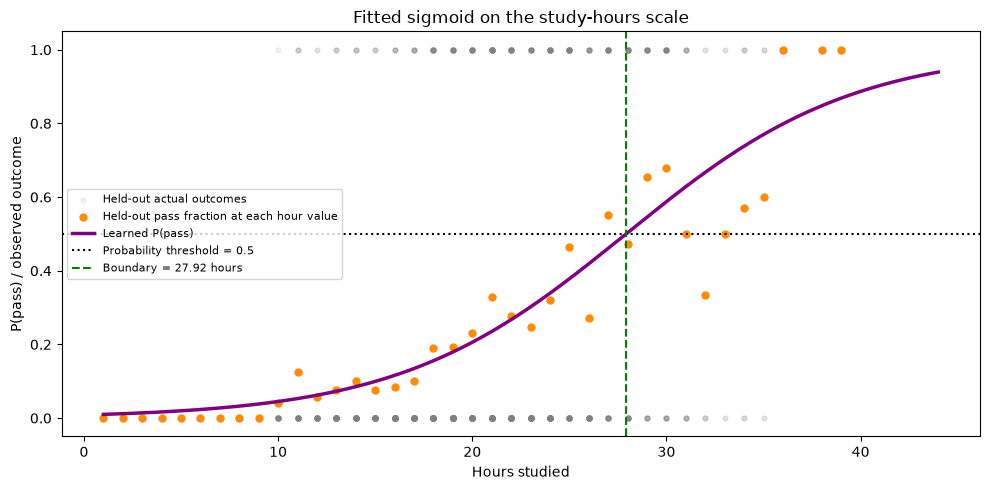

Hours | P(pass) | Predicted outcome
 12.0 |   0.062 | Fail
 20.0 |   0.206 | Fail
 28.0 |   0.503 | Pass


In [9]:
hours_grid = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
p_grid = predict_proba((hours_grid - mu) / scale, w, b)
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(X_test.ravel(), y_test, s=12, alpha=0.1, color='grey', label='Held-out actual outcomes')
unique_hours, counts = np.unique(X_test[:, 0], return_counts=True)
observed_rates = np.array([y_test[X_test[:, 0] == h].mean() for h in unique_hours])
ax.scatter(unique_hours, observed_rates, s=25, color='darkorange', label='Held-out pass fraction at each hour value')
ax.plot(hours_grid.ravel(), p_grid, color='purple', linewidth=2.5, label='Learned P(pass)')
ax.axhline(0.5, color='black', linestyle=':', label='Probability threshold = 0.5')
if boundary is not None and X.min() <= boundary <= X.max():
    ax.axvline(boundary, color='green', linestyle='--', label=f'Boundary = {boundary:.2f} hours')
ax.set(xlabel='Hours studied', ylabel='P(pass) / observed outcome', ylim=(-0.05, 1.05), title='Fitted sigmoid on the study-hours scale')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
examples = np.quantile(X_train[:, 0], [0.1, 0.5, 0.9]).reshape(-1, 1)
example_probs = predict_proba((examples - mu) / scale, w, b)
print('Hours | P(pass) | Predicted outcome')
for hours, probability in zip(examples.ravel(), example_probs):
    print(f'{hours:5.1f} | {probability:7.3f} | {"Pass" if probability >= 0.5 else "Fail"}')

10. **Talking points and reflections**


    1. Data, labels, and overlapping outcomes — We replaced hand-entered observations with the Kaggle CSV, retained study hours as the only feature, and defined Pass using a documented score cutoff of 70. The exam score creates the answer and never enters the inputs. Equal study hours can lead to different outcomes, so a probability model cannot classify everyone correctly.When identical study-hour values have conflicting labels, a model using only hours and a fixed threshold cannot classify every observation correctly

    2. From cross-entropy to vectorized gradient descent — The negative Bernoulli log-likelihood gives BCE. The sigmoid and BCE derivatives simplify to p - y, giving X.T @ (p - y) / n for the weights and the mean residual for the bias. We update both from the same parameter state, use stable sigmoid and logit loss, and verify the derivatives using finite differences. Probabilities tell us how confident the model is and provide a smooth signal for learning. Thresholded labels discard that information.We therefore train using probabilities and BCE, then apply a threshold when we need a Pass/Fail decision.

    3. Classification, visualization, and  evaluation — A 0.5 probability threshold is equivalent to a zero-logit threshold. The curve is plotted against actual hours after applying training-only standardization. Held-out BCE and classification metrics are compared with a baseline because accuracy can hide class imbalance. Held-out students are students the model did not train on.Falling training loss does not establish calibration, causation, or usefulness for real student decisions. Our model gets 77.14% accuracy, compared with 75.40% for that baseline. We also check:
    - BCE: How good are its predicted probabilities?
    - Precision: When it predicts Pass, how often is it right?
    - Recall: How many actual passing students does it identify? 

    A lower training loss means the model is fitting the training observations better. It does not, by itself, prove:
    - Calibration: Among students given a 70% passing probability, approximately 70% actually pass.
    - Causation: Making a student study additional hours will necessarily cause them to pass.
    - Practical usefulness: The model is accurate and reliable enough to guide real student decisions.
    



The final code cell produces a results summary from this run. Changing the data, pass mark, or split changes the results; we can experiment repeatedl by keeping a fresh test set for final evaluation.

Interpretation of the included run: Test accuracy is 77.14%, only modestly above the 75.40% majority baseline; BCE improves from 0.55793 to 0.48735. Pass recall is 24.3%, so the model misses many actual passing students at the 0.5 probability threshold. Hours alone is a limited predictor. 

The CSV contains a score of 101; it is retained and flagged here for investigation rather than silently changed. 

The learned boundary is about 27.92 hours. 

In [10]:
test_loss, test_accuracy, test_precision, test_recall, _ = evaluate(Xs_test, y_test)
assert np.isfinite(history).all() and history[-1] <= history[0]
assert np.all((p_grid >= 0) & (p_grid <= 1))
print(f'Rows: {len(y):,}; Pass defined as Exam_Score >= {PASS_MARK:g}.')
print(f'Gradient descent converged: {converged}; training BCE {history[0]:.5f} -> {history[-1]:.5f}.')
print(f'Test BCE: {test_loss:.5f} versus baseline {baseline_bce:.5f}.')
print(f'Test accuracy: {test_accuracy:.3%} versus majority baseline {baseline_accuracy:.3%}.')
print('Gradient, numerical stability, split, threshold, and parameter-conversion checks passed.')

Rows: 6,607; Pass defined as Exam_Score >= 70.
Gradient descent converged: True; training BCE 0.69315 -> 0.48220.
Test BCE: 0.48735 versus baseline 0.55793.
Test accuracy: 77.139% versus majority baseline 75.397%.
Gradient, numerical stability, split, threshold, and parameter-conversion checks passed.


Test BCE improved from 0.558 to 0.487, while accuracy improved only modestly. The probabilities became better overall, but many did not cross the threshold needed to change the classifications.